# Maintenance prédictive du TRS — Atelier Zone Franche Togo
## Projet Big Data — UE INF2224, Extraction d'Information
**KOUTSAVA Kossi Epiphane — Master 1 Big Data — UCAO-UUT**

Ce notebook présente, étape par étape, la démarche Data Science menant aux modèles
de **maintenance prédictive** du Taux de Rendement Synthétique (TRS) :

1. Chargement et exploration des données (EDA)
2. Calcul du TRS et de ses composantes
3. Analyse des corrélations
4. Construction des variables explicatives (features)
5. Modèle 1 — Prévision du TRS (régression linéaire)
6. Modèle 2 — Prédiction du risque de panne (Random Forest) : train/test, évaluation
7. Interprétation (importance des variables)
8. Export des modèles pour le tableau de bord

> Le notebook réalise l'**exploration et l'entraînement** ; le tableau de bord (`app.py`)
> charge ensuite le modèle exporté. C'est la séparation usuelle entre expérimentation
> et produit.

## 1. Imports et chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# Données de production (générées par generer_donnees.py)
df = pd.read_csv("production.csv")
df["date"] = pd.to_datetime(df["date"])
print("Dimensions :", df.shape)
df.head()

Dimensions : (450, 10)


,machine,date,temps_prevu,temps_marche,prod_theorique,prod_reelle,pieces_bonnes,nb_arrets,micro_arrets,temp_moteur
0,M-01,2026-02-02,450,427,1139,1065,1063,0,1,69.6
1,M-01,2026-02-03,450,424,1131,1103,1084,0,2,63.8
2,M-01,2026-02-04,450,433,1155,1024,1009,0,2,62.8
3,M-01,2026-02-05,450,450,1200,1145,1135,0,0,63.5
4,M-01,2026-02-06,450,408,1088,1059,1052,1,1,64.9


## 2. Exploration des données (EDA)

In [3]:
# Aperçu général
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   machine         450 non-null    str           
 1   date            450 non-null    datetime64[us]
 2   temps_prevu     450 non-null    int64         
 3   temps_marche    450 non-null    int64         
 4   prod_theorique  450 non-null    int64         
 5   prod_reelle     450 non-null    int64         
 6   pieces_bonnes   450 non-null    int64         
 7   nb_arrets       450 non-null    int64         
 8   micro_arrets    450 non-null    int64         
 9   temp_moteur     450 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(7), str(1)
memory usage: 37.0 KB


,date,temps_prevu,temps_marche,prod_theorique,prod_reelle,pieces_bonnes,nb_arrets,micro_arrets,temp_moteur
count,450,450.0,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,2026-04-04 12:00:00,450.0,388.257778,1035.340000,972.813333,951.386667,2.537778,4.180000,68.684222
min,2026-02-02 00:00:00,450.0,224.000000,597.000000,523.000000,509.000000,0.000000,0.000000,56.500000
25%,2026-03-04 00:00:00,450.0,371.000000,989.000000,896.250000,864.250000,1.000000,2.000000,65.300000
50%,2026-04-04 12:00:00,450.0,400.000000,1067.000000,999.000000,975.500000,2.000000,3.000000,67.900000
75%,2026-05-06 00:00:00,450.0,421.000000,1123.000000,1058.750000,1040.500000,3.000000,6.000000,71.375000
max,2026-06-05 00:00:00,450.0,450.000000,1200.000000,1199.000000,1198.000000,14.000000,16.000000,90.200000
std,NaN,0.0,45.342107,120.909149,122.331238,124.354088,2.418313,3.039612,4.951335


In [4]:
# Nombre de relevés par machine
df["machine"].value_counts().sort_index()

machine
M-01    90
M-02    90
M-03    90
M-04    90
M-05    90
Name: count, dtype: int64

In [5]:
# Nettoyage : cohérences physiques de base
n0 = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=["temps_prevu","temps_marche","prod_theorique",
                       "prod_reelle","pieces_bonnes"])
df = df[df["temps_marche"] <= df["temps_prevu"]]
df = df[df["pieces_bonnes"] <= df["prod_reelle"]]
print(f"Lignes : {n0} -> {len(df)} après nettoyage ({n0-len(df)} rejetées)")

Lignes : 450 -> 450 après nettoyage (0 rejetées)


## 3. Calcul du TRS et de ses composantes

In [6]:
df["dispo"] = df["temps_marche"] / df["temps_prevu"]
df["perf"]  = df["prod_reelle"]  / df["prod_theorique"]
df["qual"]  = df["pieces_bonnes"] / df["prod_reelle"]
df["trs"]   = df["dispo"] * df["perf"] * df["qual"]

print("TRS global de l'atelier : {:.1%}".format(df["trs"].mean()))
df.groupby("machine")[["dispo","perf","qual","trs"]].mean().round(3)

TRS global de l'atelier : 79.3%


,dispo,perf,qual,trs
machine,,,,
M-01,0.932,0.943,0.990,0.869
M-02,0.894,0.930,0.972,0.808
M-03,0.714,0.949,0.981,0.665
M-04,0.837,0.917,0.958,0.735
M-05,0.938,0.957,0.988,0.887


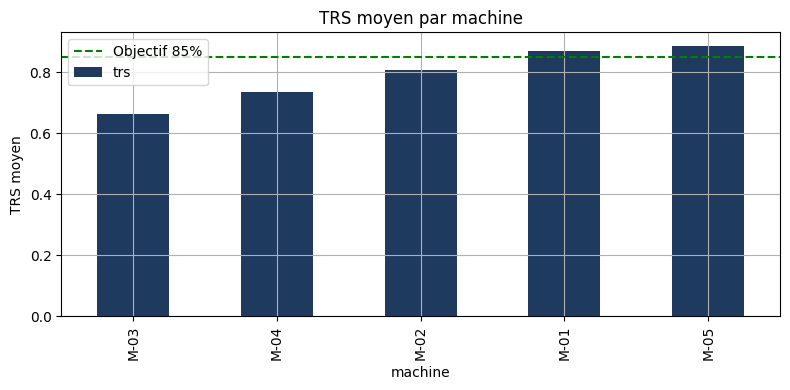

In [7]:
# Visualisation : TRS moyen par machine
trs_m = df.groupby("machine")["trs"].mean().sort_values()
ax = trs_m.plot(kind="bar", color="#1F3A5F")
ax.axhline(0.85, color="green", linestyle="--", label="Objectif 85%")
ax.set_ylabel("TRS moyen"); ax.set_title("TRS moyen par machine")
ax.legend(); plt.tight_layout(); plt.show()

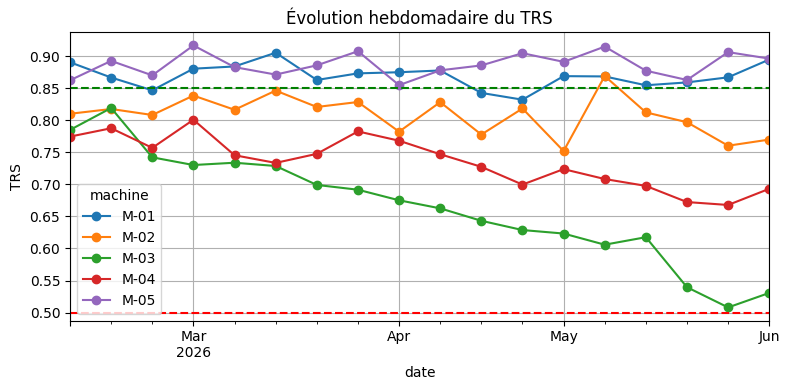

In [8]:
# Evolution du TRS dans le temps (moyenne hebdomadaire par machine)
pivot = (df.groupby([pd.Grouper(key="date", freq="W"), "machine"])["trs"]
           .mean().unstack())
pivot.plot(marker="o")
plt.axhline(0.85, color="green", linestyle="--")
plt.axhline(0.50, color="red", linestyle="--")
plt.ylabel("TRS"); plt.title("Évolution hebdomadaire du TRS"); plt.tight_layout(); plt.show()

On observe que **M-03 se dégrade** nettement au fil du temps : son TRS décroît et
s'approche du seuil critique. C'est le signal que les modèles vont exploiter.

## 4. Analyse des corrélations

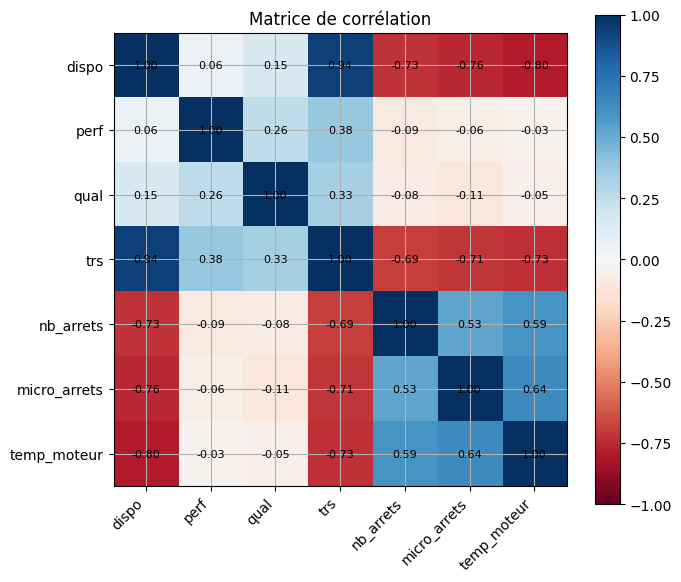

In [9]:
# Corrélations entre signaux et TRS
cols = ["dispo","perf","qual","trs","nb_arrets","micro_arrets","temp_moteur"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); plt.title("Matrice de corrélation"); plt.tight_layout(); plt.show()

Le TRS est fortement lié à la **disponibilité**. Les **arrêts**, **micro-arrêts** et
la **température moteur** sont corrélés négativement au TRS : ce sont de bons indicateurs
précurseurs d'une dégradation.

## 5. Modèle 1 — Prévision du TRS (régression linéaire)

Pour chaque machine, on ajuste une droite de tendance sur le TRS journalier et on
projette les prochains jours. On illustre sur **M-03**.

Pente : -0.314 pt de TRS / jour
TRS projeté dans 15 jours : 47.8%


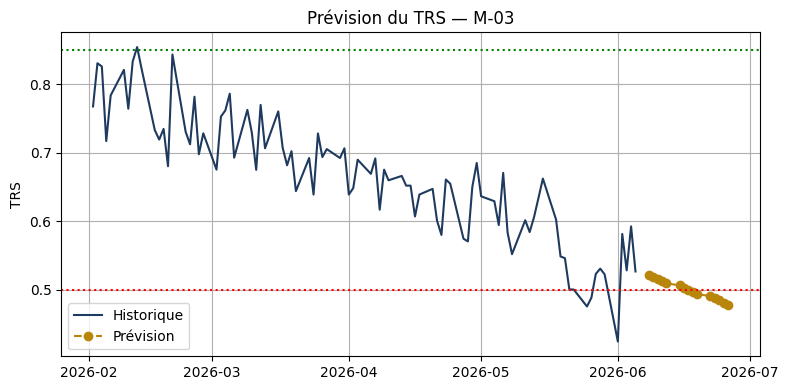

In [10]:
def prevoir_trs(d, n_jours=15):
    d = d.sort_values("date").reset_index(drop=True)
    X = np.arange(len(d)).reshape(-1,1)
    y = d["trs"].values
    m = LinearRegression().fit(X, y)
    Xf = np.arange(len(d), len(d)+n_jours).reshape(-1,1)
    yf = np.clip(m.predict(Xf), 0, 1)
    dates_f = pd.bdate_range(d["date"].max()+pd.Timedelta(days=1), periods=n_jours)
    return m, dates_f, yf

dfm = df[df["machine"]=="M-03"]
modele_tendance, dts, yf = prevoir_trs(dfm, 15)
print(f"Pente : {modele_tendance.coef_[0]*100:+.3f} pt de TRS / jour")
print(f"TRS projeté dans 15 jours : {yf[-1]:.1%}")

hist = dfm.sort_values("date")
plt.plot(hist["date"], hist["trs"], color="#1F3A5F", label="Historique")
plt.plot(dts, yf, "o--", color="#B8860B", label="Prévision")
plt.axhline(0.85, color="green", linestyle=":"); plt.axhline(0.50, color="red", linestyle=":")
plt.ylabel("TRS"); plt.title("Prévision du TRS — M-03"); plt.legend(); plt.tight_layout(); plt.show()

## 6. Modèle 2 — Prédiction du risque de panne (Random Forest)

### 6.1 Construction des variables explicatives (features)
On décrit l'état **récent** de chaque machine sur une fenêtre glissante de 5 jours,
et on définit la cible : une **panne** (TRS < 0,50) survient-elle dans les 5 jours suivants ?

In [11]:
FENETRE, HORIZON, SEUIL = 5, 5, 0.50

lignes = []
for machine, g in df.groupby("machine"):
    g = g.sort_values("date").reset_index(drop=True)
    for i in range(FENETRE, len(g)-HORIZON):
        fen = g.iloc[i-FENETRE:i]
        fut = g.iloc[i:i+HORIZON]
        pente = np.polyfit(np.arange(FENETRE), fen["trs"].values, 1)[0]
        lignes.append({
            "machine": machine, "date": g.iloc[i]["date"],
            "trs_moyen": fen["trs"].mean(),
            "trs_pente": pente,
            "dispo_moyenne": fen["dispo"].mean(),
            "arrets_moyens": fen["nb_arrets"].mean(),
            "micro_moyens": fen["micro_arrets"].mean(),
            "temp_moyenne": fen["temp_moteur"].mean(),
            "panne_future": int((fut["trs"] < SEUIL).any()),
        })
feats = pd.DataFrame(lignes)
print("Echantillons :", len(feats), "| pannes :", int(feats["panne_future"].sum()))
feats.head()

Echantillons : 400 | pannes : 9


,machine,date,trs_moyen,trs_pente,dispo_moyenne,arrets_moyens,micro_moyens,temp_moyenne,panne_future
0,M-01,2026-02-09,0.890346,0.002495,0.952000,0.2,1.2,64.92,0
1,M-01,2026-02-10,0.884232,-0.006006,0.946222,0.6,2.2,64.88,0
2,M-01,2026-02-11,0.860736,-0.020084,0.935556,0.8,2.4,65.28,0
3,M-01,2026-02-12,0.877618,-0.013275,0.933778,0.8,2.2,66.18,0
4,M-01,2026-02-13,0.869671,0.012887,0.922667,0.8,3.0,66.42,0


### 6.2 Séparation train / test

In [12]:
FEATURES = ["trs_moyen","trs_pente","dispo_moyenne",
            "arrets_moyens","micro_moyens","temp_moyenne"]
X = feats[FEATURES]
y = feats["panne_future"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
print(f"Train : {len(X_tr)}  |  Test : {len(X_te)}")
print(f"Pannes dans le train : {y_tr.sum()}  |  dans le test : {y_te.sum()}")

Train : 280  |  Test : 120
Pannes dans le train : 6  |  dans le test : 3


### 6.3 Entraînement du modèle

In [13]:
modele_risque = RandomForestClassifier(
    n_estimators=200, max_depth=6, random_state=42, class_weight="balanced")
modele_risque.fit(X_tr, y_tr)
y_pred = modele_risque.predict(X_te)
print("Modèle entraîné.")

Modèle entraîné.


### 6.4 Évaluation

In [14]:
print("Exactitude (accuracy) : {:.2f}".format(accuracy_score(y_te, y_pred)))
print("Précision           : {:.2f}".format(precision_score(y_te, y_pred, zero_division=0)))
print("Rappel (recall)     : {:.2f}".format(recall_score(y_te, y_pred, zero_division=0)))
print("Score F1            : {:.2f}".format(f1_score(y_te, y_pred, zero_division=0)))

Exactitude (accuracy) : 0.98
Précision           : 1.00
Rappel (recall)     : 0.33
Score F1            : 0.50


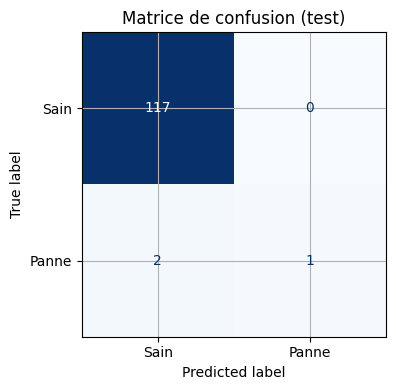

In [15]:
cm = confusion_matrix(y_te, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Sain","Panne"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Matrice de confusion (test)"); plt.tight_layout(); plt.show()

**Lecture critique (démarche d'ingénieur).** Les pannes sont rares dans l'historique
(classes déséquilibrées), ce qui limite le rappel : le modèle est prudent mais peut manquer
des cas. Pistes d'amélioration : collecter plus d'historique, rééquilibrer les classes
(SMOTE), ou abaisser le seuil de décision pour privilégier le rappel.

### 6.5 Interprétation — importance des variables

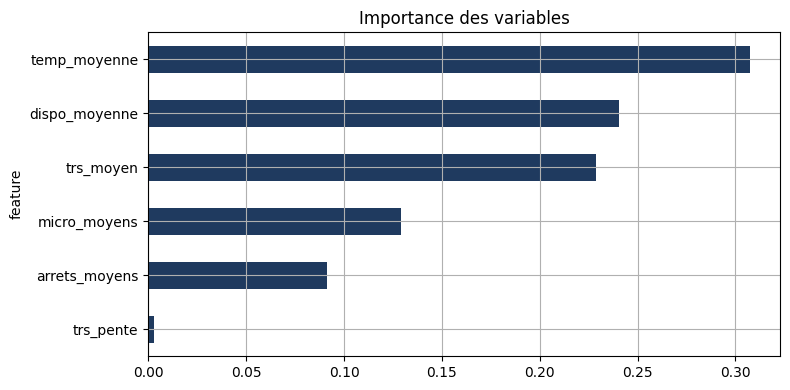

,feature,importance
5,temp_moyenne,0.307394
2,dispo_moyenne,0.240729
0,trs_moyen,0.228531
4,micro_moyens,0.128875
3,arrets_moyens,0.091304
1,trs_pente,0.003167


In [16]:
imp = (pd.DataFrame({"feature": FEATURES,
                     "importance": modele_risque.feature_importances_})
         .sort_values("importance"))
imp.plot(kind="barh", x="feature", y="importance", color="#1F3A5F", legend=False)
plt.title("Importance des variables"); plt.xlabel(""); plt.tight_layout(); plt.show()
imp.sort_values("importance", ascending=False)

### 6.6 Risque actuel par machine

In [17]:
lignes = []
for machine, g in feats.groupby("machine"):
    derniere = g.sort_values("date").iloc[-1]
    proba = modele_risque.predict_proba(derniere[FEATURES].to_frame().T)[0][1]
    lignes.append({"machine": machine, "probabilite_panne": proba})
risque = pd.DataFrame(lignes).sort_values("probabilite_panne", ascending=False)
risque["niveau"] = pd.cut(risque["probabilite_panne"],
                          [-0.01,0.30,0.60,1.01], labels=["FAIBLE","MODERE","ELEVE"])
risque

,machine,probabilite_panne,niveau
2,M-03,0.905,ELEVE
0,M-01,0.000,FAIBLE
1,M-02,0.000,FAIBLE
3,M-04,0.000,FAIBLE
4,M-05,0.000,FAIBLE


## 7. Export des modèles pour le tableau de bord

On sauvegarde le modèle de risque entraîné (et la liste des features) avec `joblib`.
Le tableau de bord `app.py` chargera ce fichier au lieu de réentraîner le modèle.

In [18]:
artefact = {"modele": modele_risque, "features": FEATURES,
            "fenetre": FENETRE, "horizon": HORIZON, "seuil": SEUIL}
joblib.dump(artefact, "modele_risque.joblib")
print("Modèle exporté -> modele_risque.joblib")

Modèle exporté -> modele_risque.joblib


## Conclusion

Ce notebook a couvert l'ensemble de la démarche : exploration, calcul du TRS, analyse des
corrélations, construction des features, et l'entraînement de **deux modèles** (prévision du
TRS et prédiction du risque de panne), avec évaluation et interprétation. Le modèle exporté
alimente le tableau de bord, qui constitue le produit final destiné au décideur.